In [2]:
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

**Сценарий:** Представьте, что вы работаете в розничной компании, которая недавно запустила программу лояльности. Компания хочет оценить влияние программы на расходы клиентов. Программа лояльности была развернута в выбранных магазинах (экспериментальная группа), в то время как другие магазины продолжили работу без нее (контрольная группа). У нас есть данные о расходах клиентов до и после запуска программы, и мы хотим оценить, привела ли программа к увеличению выручки, контролируя другие факторы, такие как возраст клиентов и средний доход в месте расположения магазина.

#### Задание 1
Для вас подготовлен csv файл под названием DID_test.csv.<br>
В данном датасете есть следющие колонки: 
* Новый_Маркетинг - флаг, обозначающий проходила ли программа лояльности в данном магазине
* После_Обновления - флаг, обозначающий время замера показателей после или до проведения программы лояльности
* Возраст_Посетителей - средний возраст посетитиелей магазина
* Доход_Посетителей - средний годовой доход посетителей магазина в год
* Выручка_Магазина - выручка магазина за месяц в долларах

Вам необходимо, используя библиотке stasmodels, провести линейную регрессию для прогноза Выручки_Магазина

In [1]:
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

In [2]:
# Загрузка данных
df = pd.read_csv('DID_test.csv')

In [3]:
# Проверка данных
print(df.head())
print(df.info())
print(df.isnull().sum())

   Новый_Маркетинг  После_Обновления  Возраст_Посетителей  Доход_Посетителей  \
0                1                 0                   25       48887.960002   
1                1                 0                   41       37998.682623   
2                1                 1                   56       63264.716683   
3                1                 0                   22       45506.956139   
4                1                 0                   61       44031.026684   

   Выручка_Магазина  
0        283.368654  
1        319.693095  
2        423.218242  
3        298.164762  
4        360.640089  
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Новый_Маркетинг      200 non-null    int64  
 1   После_Обновления     200 non-null    int64  
 2   Возраст_Посетителей  200 non-null    int64  
 3   Доход_Посетителей    200 non-null    fl

In [4]:
# Признаки и целевая переменная
X = df[
    ['Новый_Маркетинг', 'После_Обновления',
     'Возраст_Посетителей', 'Доход_Посетителей']
]

y = df['Выручка_Магазина']

In [5]:
# Добавление константы
X = sm.add_constant(X)

In [6]:
# Построение линейной регрессии
model = sm.OLS(y, X).fit()

# Результаты модели
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:       Выручка_Магазина   R-squared:                       0.640
Model:                            OLS   Adj. R-squared:                  0.633
Method:                 Least Squares   F-statistic:                     86.63
Date:                Fri, 16 Oct 2026   Prob (F-statistic):           3.57e-42
Time:                        11:51:29   Log-Likelihood:                -923.84
No. Observations:                 200   AIC:                             1858.
Df Residuals:                     195   BIC:                             1874.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                 201.2975    

#### Задание 2
Интерпретируйте полученные результаты

In [7]:
1#R-squared — доля вариации выручки, объясняемая моделью. Чем ближе значение к 1, тем лучше модель объясняет данные.

2#coef — коэффициент регрессии, показывающий направление и величину связи признака с выручкой при прочих равных условиях.

3#P>|t| — p-value для проверки статистической значимости коэффициента. Обычно коэффициент считают значимым, если p-value меньше 0,05.

3#const — константа модели.

4#Новый_Маркетинг — разница между экспериментальной и контрольной группами в базовом периоде при прочих равных условиях.
5#После_Обновления — изменение выручки после запуска программы, общее для обеих групп при прочих равных условиях.

5

#### Задание 3
Добавьте новую колонку под названием *intersection* которая будет перемножением колонок Новый_Маркетинг и После_Обновления<br>
Данная колонка будет служить признаком для Difference-In-Difference анализа<br>
Постройте линейную регрессую с учетом нового признака

In [8]:
# Создание признака взаимодействия
df['intersection'] = (
    df['Новый_Маркетинг'] * df['После_Обновления']
)

In [9]:
# Формирование признаков для DiD-модели
X_did = df[
    ['Новый_Маркетинг', 'После_Обновления',
     'intersection', 'Возраст_Посетителей',
     'Доход_Посетителей']
]

y = df['Выручка_Магазина']

In [10]:
# Добавление константы
X_did = sm.add_constant(X_did)


In [11]:
# Построение DiD-регрессии
model_did = sm.OLS(y, X_did).fit()

# Вывод результатов
print(model_did.summary())

                            OLS Regression Results                            
Dep. Variable:       Выручка_Магазина   R-squared:                       0.661
Model:                            OLS   Adj. R-squared:                  0.652
Method:                 Least Squares   F-statistic:                     75.71
Date:                Fri, 16 Oct 2026   Prob (F-statistic):           1.02e-43
Time:                        11:54:14   Log-Likelihood:                -917.75
No. Observations:                 200   AIC:                             1847.
Df Residuals:                     194   BIC:                             1867.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                 211.7953    

In [12]:
# Отдельно выводим эффект программы лояльности
print("\nЭффект программы лояльности (DiD):")
print("Коэффициент:", model_did.params['intersection'])
print("P-value:", model_did.pvalues['intersection'])


Эффект программы лояльности (DiD):
Коэффициент: 24.09597133379632
P-value: 0.0005982802217607564


#### Задание 4
Интерпретируйте новые результаты

In [13]:
1#Если коэффициент положительный, программа связана с дополнительным ростом выручки экспериментальной группы относительно контрольной группы.

2#Если коэффициент отрицательный, относительное изменение выручки экспериментальной группы оказалось хуже.

3#Если P>|t| для intersection меньше 0,05, эффект статистически значим на уровне 5%.

4#Если p-value больше или равно 0,05, недостаточно статистических оснований утверждать, что эффект отличается от нуля.

4

In [14]:
#Для причинной интерпретации необходимо, в частности, предположение о параллельных трендах:
#без программы выручка экспериментальной и контрольной групп менялась бы сопоставимым образом.

#### Задание 5
Нарисуйте график, показывающий динамику изменений средней выручки между экспериментальной и контрольной группами, до и после кампании

In [15]:
# Расчет средней выручки по группам и периодам
group_means = df.groupby(
    ['Новый_Маркетинг', 'После_Обновления']
)['Выручка_Магазина'].mean().reset_index()

In [16]:
# Переименование категорий для графика
group_means['Группа'] = group_means['Новый_Маркетинг'].map({
    0: 'Контрольная группа',
    1: 'Экспериментальная группа'
})

group_means['Период'] = group_means['После_Обновления'].map({
    0: 'До программы',
    1: 'После программы'
})

In [17]:
# Подготовка данных для графика
pivot_data = group_means.pivot(
    index='Период',
    columns='Группа',
    values='Выручка_Магазина'
)

In [18]:
# Сохраняем правильный порядок периодов
pivot_data = pivot_data.reindex(
    ['До программы', 'После программы']
)


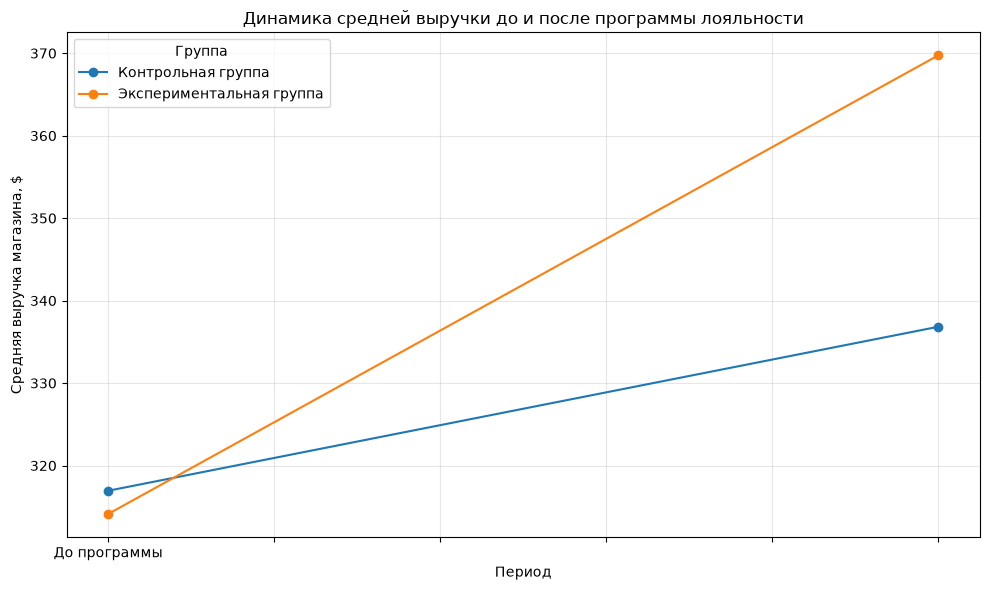

In [19]:
# Построение графика
pivot_data.plot(
    kind='line',
    marker='o',
    figsize=(10, 6)
)

plt.title('Динамика средней выручки до и после программы лояльности')
plt.xlabel('Период')
plt.ylabel('Средняя выручка магазина, $')
plt.grid(True, alpha=0.3)
plt.legend(title='Группа')
plt.tight_layout()
plt.show()